# 客户流失预测模型

## 1. 项目目标

基于已清洗的 IBM Telco Customer Churn 数据，建立机器学习模型，识别具有较高流失风险的客户。

本阶段主要完成：
- 特征与目标变量选择
- 训练集和测试集划分
- 数据预处理
- Logistic Regression 模型训练
- 模型评估与业务解释

In [1]:
import pandas as pd
model_df = pd.read_csv("../data/processed/customer_churn_cleaned.csv")
model_df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
feature_columns = ["tenure", "MonthlyCharges", "Contract", "InternetService", "TechSupport"]
x = model_df[feature_columns]
x.head()

,tenure,MonthlyCharges,Contract,InternetService,TechSupport
0,1,29.85,Month-to-month,DSL,No
1,34,56.95,One year,DSL,No
2,2,53.85,Month-to-month,DSL,No
3,45,42.30,One year,DSL,Yes
4,2,70.70,Month-to-month,Fiber optic,No


In [3]:
y = model_df["Churn"].map({"No":0, "Yes":1})
y.value_counts()

Churn
0    5174
1    1869
Name: count, dtype: int64

In [4]:
print("x的形状:", x.shape)
print("y的形状:", y.shape)
print("目标变量分布:")
print(y.value_counts())

x的形状: (7043, 5)
y的形状: (7043,)
目标变量分布:
Churn
0    5174
1    1869
Name: count, dtype: int64


## 2. 训练集与测试集划分

为了评估模型对未见数据的预测能力，将数据按照80%和20%的比例划分为训练集和测试集。

使用分层抽样，以尽量保持两个数据集中客户流失与未流失的比例一致。

In [5]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [6]:
from sklearn.model_selection import train_test_split

In [7]:
x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [8]:
x_train_fit, x_val, y_train_fit,y_val = train_test_split(
    x_train, y_train, test_size = 0.25, random_state = 42, stratify = y_train
)
print("新训练集：", x_train_fit.shape)
print("验证集：", x_val.shape)
print("原测试集：", x_test.shape)

新训练集： (4225, 5)
验证集： (1409, 5)
原测试集： (1409, 5)


In [9]:
print("X_train:", x_train.shape)
print("X_test:", x_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (5634, 5)
X_test: (1409, 5)
y_train: (5634,)
y_test: (1409,)


In [10]:
print("训练集：")
print(y_train.value_counts(normalize=True).round(3))
print("测试集：")
print(y_test.value_counts(normalize=True).round(3))

训练集：
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64
测试集：
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64


In [11]:
x_train["Contract"].unique()

<StringArray>
['Month-to-month', 'Two year', 'One year']
Length: 3, dtype: str

In [12]:
contract_sample = x_train[["Contract"]].head(5)
contract_sample

,Contract
3738,Month-to-month
3151,Month-to-month
4860,Two year
3867,Two year
3810,Month-to-month


In [13]:
pd.get_dummies(contract_sample, dtype = int)

,Contract_Month-to-month,Contract_Two year
3738,1,0
3151,1,0
4860,0,1
3867,0,1
3810,1,0


## 3. 分类变量编码

### 3.1 One-Hot Encoding 原理

由于合同类型等分类变量无法直接作为普通 Logistic Regression 模型的数值输入，本节使用 OneHotEncoder 将其转换为数值特征。

编码器仅从训练集学习转换规则，然后将相同规则应用到测试集，避免不必要的数据泄漏。

In [14]:
from sklearn.preprocessing import OneHotEncoder

contract_encoder = OneHotEncoder(handle_unknown = "ignore", sparse_output = False, dtype = int)

In [15]:
contract_encoder.fit(x_train[["Contract"]])
print("编码器已完成fit")

编码器已完成fit


In [16]:
contract_encoder.categories_

[array(['Month-to-month', 'One year', 'Two year'], dtype=object)]

In [17]:
contract_sample = x_train[["Contract"]].head(5)

In [18]:
encoded_array = contract_encoder.transform(contract_sample)
encoded_array

array([[1, 0, 0],
       [1, 0, 0],
       [0, 0, 1],
       [0, 0, 1],
       [1, 0, 0]])

In [19]:
train_encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False,
    dtype=int
)

train_encoded = train_encoder.fit_transform(
    x_train[["Contract"]]
)

In [20]:
contract_encoder.transform(contract_sample)

array([[1, 0, 0],
       [1, 0, 0],
       [0, 0, 1],
       [0, 0, 1],
       [1, 0, 0]])

In [21]:
test_encoded = train_encoder.transform(
    x_test[["Contract"]]
)

In [22]:
print("训练集编码后：", train_encoded.shape)
print("测试集编码后：", test_encoded.shape)

训练集编码后： (5634, 3)
测试集编码后： (1409, 3)


In [23]:
sample = x_test[["Contract"]].head(3)
sample

,Contract
437,Two year
2280,Month-to-month
2235,One year


In [24]:
result = train_encoder.transform(sample)
result

array([[0, 0, 1],
       [1, 0, 0],
       [0, 1, 0]])

In [25]:
print("转换前：", sample.shape)
print("转换后：", result.shape)

print("编码后的列名：")
print(train_encoder.get_feature_names_out(["Contract"]))

print("编码结果：")
print(result)

转换前： (3, 1)
转换后： (3, 3)
编码后的列名：
['Contract_Month-to-month' 'Contract_One year' 'Contract_Two year']
编码结果：
[[0 0 1]
 [1 0 0]
 [0 1 0]]


### One-Hot Encoding 学习总结

1. fit()：从训练集学习分类变量的类别及编码规则。
2. transform()：使用已学习的规则转换数据。
3. fit_transform()：学习规则并立即转换数据。
4. 训练集使用 fit_transform()，测试集使用 transform()。
5. 独热编码会增加特征列数，但不会改变客户记录数量。

## 3.2 多类型特征预处理（ColumnTransformer）

本节将数值变量与分类变量分开处理，为后续机器学习模型训练准备统一的数值特征矩阵。

In [26]:
x_train.dtypes

tenure               int64
MonthlyCharges     float64
Contract               str
InternetService        str
TechSupport            str
dtype: object

In [27]:
numeric_features = ["tenure", "MonthlyCharges"]
categorical_features = ["Contract", "InternetService", "TechSupport"]

In [28]:
x_train[numeric_features].head()

,tenure,MonthlyCharges
3738,35,49.20
3151,15,75.10
4860,13,40.55
3867,26,73.50
3810,1,44.55


In [29]:
x_train[categorical_features].head()

,Contract,InternetService,TechSupport
3738,Month-to-month,DSL,No
3151,Month-to-month,Fiber optic,No
4860,Two year,DSL,Yes
3867,Two year,DSL,No
3810,Month-to-month,DSL,No


In [30]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

In [31]:
preprocessor_demo = ColumnTransformer(
    transformers = [("num", "passthrough", numeric_features), 
                    ("cat", OneHotEncoder(handle_unknown = "ignore", sparse_output = False), 
                     categorical_features)])

In [32]:
x_train_demo = preprocessor_demo.fit_transform(x_train)
x_test_demo = preprocessor_demo.transform(x_test)

In [33]:
print("处理前：", x_train.shape)
print("处理后：", x_train_demo.shape)
print("测试集处理后：", x_test_demo.shape)

处理前： (5634, 5)
处理后： (5634, 11)
测试集处理后： (1409, 11)


## 3.3 数值特征标准化（StandardScaler）

本节对 tenure 和 MonthlyCharges 进行标准化，降低不同数值特征尺度差异对模型训练的影响。

标准化器仅从训练集计算平均值和标准差，再将相同规则应用于测试集。

In [34]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

In [35]:
scaled_train = scaler.fit_transform(x_train[numeric_features])

In [36]:
print("训练集平均值：", scaler.mean_)
print("训练集标准差：", scaler.scale_)

训练集平均值： [32.48509052 64.92996095]
训练集标准差： [24.56656302 30.13543058]


In [37]:
scaled_test = scaler.transform(x_test[numeric_features])

In [38]:
print("训练集标准化前：", x_train[numeric_features].shape)
print("训练集标准化后：", scaled_train.shape)
print("测试集标准化后：", scaled_test.shape)

训练集标准化前： (5634, 2)
训练集标准化后： (5634, 2)
测试集标准化后： (1409, 2)


In [39]:
scaled_df = pd.DataFrame(scaled_train, columns = numeric_features, index = x_train.index)
scaled_df.head()

,tenure,MonthlyCharges
3738,0.102371,-0.521976
3151,-0.711743,0.337478
4860,-0.793155,-0.809013
3867,-0.263980,0.284384
3810,-1.281624,-0.676279


In [40]:
print("需要处理的特征：", numeric_features)

print("平均值：", scaler.mean_)

print("标准化使用的尺度：", scaler.scale_)

需要处理的特征： ['tenure', 'MonthlyCharges']
平均值： [32.48509052 64.92996095]
标准化使用的尺度： [24.56656302 30.13543058]


## 3.4 完整数值与分类特征预处理

本节使用 ColumnTransformer 统一处理不同类型的变量：

- 数值变量使用 StandardScaler 标准化。
- 分类变量使用 OneHotEncoder 编码。
- 只在训练集上学习预处理规则，并应用到测试集。

In [41]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor = ColumnTransformer(
    transformers = [
        (
            "num", StandardScaler(), numeric_features
            ),
        (
            "cat", OneHotEncoder(handle_unknown = "ignore", sparse_output = False), categorical_features
        )
    ]
)

In [42]:
x_train_ready = preprocessor.fit_transform(x_train)
x_test_ready = preprocessor.transform(x_test)

In [43]:
print("训练集处理前：", x_train.shape)
print("训练集处理后：", x_train_ready.shape)

print("测试集处理后：", x_test_ready.shape)

训练集处理前： (5634, 5)
训练集处理后： (5634, 11)
测试集处理后： (1409, 11)


In [44]:
print(preprocessor.get_feature_names_out)

<bound method ColumnTransformer.get_feature_names_out of ColumnTransformer(transformers=[('num', StandardScaler(),
                                 ['tenure', 'MonthlyCharges']),
                                ('cat',
                                 OneHotEncoder(handle_unknown='ignore',
                                               sparse_output=False),
                                 ['Contract', 'InternetService',
                                  'TechSupport'])])>


In [45]:
processor_df = pd.DataFrame(
    x_train_ready,
    columns = preprocessor.get_feature_names_out(),
    index = x_train.index
)

processor_df.head()

,num__tenure,num__MonthlyCharges,cat__Contract_Month-to-month,cat__Contract_One year,cat__Contract_Two year,cat__InternetService_DSL,cat__InternetService_Fiber optic,cat__InternetService_No,cat__TechSupport_No,cat__TechSupport_No internet service,cat__TechSupport_Yes
3738,0.102371,-0.521976,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
3151,-0.711743,0.337478,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
4860,-0.793155,-0.809013,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0
3867,-0.263980,0.284384,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0
3810,-1.281624,-0.676279,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0


### 3.5 数据预处理总结

本阶段使用 ColumnTransformer 对不同类型的客户特征进行预处理。

1. StandardScaler 对 tenure 和 MonthlyCharges 进行标准化。
2. OneHotEncoder 将 Contract、InternetService 和 TechSupport 转换为数值特征。
3. 使用 fit_transform() 在训练集上学习规则并转换数据。
4. 使用 transform() 将相同规则应用于测试集。
5. 原始5个特征经过处理后转换为11个数值特征。

预处理后的特征将用于后续的 Logistic Regression 客户流失预测模型。

In [46]:
print("训练特征：", x_train_ready.shape)
print("训练标签：", y_train.shape)
print("测试特征：", x_test_ready.shape)

训练特征： (5634, 11)
训练标签： (5634,)
测试特征： (1409, 11)


## 4. Logistic Regression 客户流失预测

### 4.1 模型训练

本阶段使用 Logistic Regression 建立基础客户流失预测模型。

模型输入为经过标准化和独热编码的客户特征，目标变量为客户是否流失。

仅使用训练集拟合模型，测试集保留用于评估模型对未见数据的预测能力。

In [47]:
from sklearn.linear_model import LogisticRegression

In [48]:
churn_model = LogisticRegression(max_iter = 1000)

In [49]:
churn_model.fit(x_train_ready, y_train)
print("训练完成")

训练完成


In [50]:
first_5_predictions = churn_model.predict(
    x_test_ready[:5]
)
first_5_predictions

array([0, 1, 0, 0, 0])

In [51]:
print("模型系数形状：", churn_model.coef_.shape)

print("前5名客户预测：")
print(churn_model.predict(x_test_ready[:5]))

模型系数形状： (1, 11)
前5名客户预测：
[0 1 0 0 0]


### 4.2 使用 Pipeline 整合数据预处理与预测模型

本节使用 Pipeline 将 ColumnTransformer 和 Logistic Regression 连接起来。

Pipeline 可以在模型训练和预测时自动执行相应的数据预处理步骤，减少手动转换数据造成的错误，并确保测试数据使用训练阶段学习到的预处理规则。

In [52]:
from sklearn.pipeline import Pipeline
churn_pipeline = Pipeline(steps = [("preprocess", preprocessor), ("model", LogisticRegression(max_iter = 1000))])

In [53]:
_ = churn_pipeline.fit(x_train, y_train)

print("Pipeline训练完成")

Pipeline训练完成


### 验证集模型训练

使用独立训练集重新训练模型，
避免验证集数据参与模型训练。

In [54]:
from sklearn.base import clone
validation_pipeline = clone(churn_pipeline)
validation_pipeline.fit(x_train_fit, y_train_fit)
val_prob = validation_pipeline.predict_proba(x_val)[:, 1]
print("训练完成!")
print("验证集预测人数:", len(val_prob))

训练完成!
验证集预测人数: 1409


In [ ]:
from sklearn.metrics import confusion_matrix
for threshold in [0.5, 0.4]:
    val_pred = (val_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_val, val_pred, labels=[0, 1]).ravel()
    precision = tp / (tp + fp) if tp + fp > 0 else 0
    recall = tp / (tp + fn) if tp + fn > 0 else 0
    cost = 10 * (tp + fp) + 25 * fn
    print(f"\n阈值:{threshold:.0%}")
    print(f"TP={tp}, FP={fp}, FN={fn}, TN={tn}")
    print(f"Precision:{precision:.1%}")
    print(f"Recall:{recall:.1%}")
    print(f"模拟成本：{cost:.0f}")


阈值:50%
TP=187, FP=99, FN=187, TN=936
Precision:65.4%
Recall:50.0%
模拟成本：7535

阈值:40%
TP=245, FP=173, FN=129, TN=862
Precision:58.6%
Recall:65.5%
模拟成本：7405


In [55]:
pipeline_prediction = churn_pipeline.predict(x_test.head(5))
print(pipeline_prediction)
pipeline_prediction

[0 1 0 0 0]


array([0, 1, 0, 0, 0])

In [56]:
print("模型系数形状：", churn_model.coef_.shape)

print("前5名客户的预测结果：")
print(churn_model.predict(x_test_ready[:5]))

模型系数形状： (1, 11)
前5名客户的预测结果：
[0 1 0 0 0]


In [57]:
print("原始测试集：", x_test.shape)
print("预处理后测试集：", x_test_ready.shape)

原始测试集： (1409, 5)
预处理后测试集： (1409, 11)


### 4.3 客户流失概率预测

除了预测客户是否流失，还需要预测客户的流失概率，以便后续结合客户价值和干预成本制定留存优先级。

In [58]:
probabilities = churn_pipeline.predict_proba(x_test.head(5))
print(probabilities)
print("结果形状:", probabilities.shape)

[[0.95556369 0.04443631]
 [0.40309005 0.59690995]
 [0.88565617 0.11434383]
 [0.53647409 0.46352591]
 [0.97633582 0.02366418]]
结果形状: (5, 2)


In [59]:
churn_pipeline.classes_

array([0, 1])

In [60]:
churn_probabilities = probabilities[:, 1]

print(churn_probabilities)

[0.04443631 0.59690995 0.11434383 0.46352591 0.02366418]


In [61]:
# 选取测试集前5名客户
sample_customers = x_test.head(5)

# 预测类别
predicted_labels = churn_pipeline.predict(sample_customers)

# 预测流失概率
predicted_probabilities = churn_pipeline.predict_proba(
    sample_customers
)[:, 1]

# 整理结果
prediction_summary = pd.DataFrame({
    "预测类别": predicted_labels,
    "预测流失概率": predicted_probabilities.round(3)
}, index=sample_customers.index)

prediction_summary

,预测类别,预测流失概率
437,0,0.044
2280,1,0.597
2235,0,0.114
4460,0,0.464
3761,0,0.024


In [62]:
sample = x_test.head(2)

print("处理前：")
print(sample[["tenure", "MonthlyCharges"]])

processed = churn_pipeline.named_steps["preprocess"].transform(sample)

print("处理后：")
print(processed[:, :2])

处理前：
      tenure  MonthlyCharges
437       72          114.05
2280       8          100.15
处理后：
[[ 1.60848343  1.62997635]
 [-0.9966836   1.16872526]]


In [63]:
# 取出前3名测试客户
sample = x_test.head(3)

# 预测是否流失
labels = churn_pipeline.predict(sample)

# 预测两个类别的概率
probabilities = churn_pipeline.predict_proba(sample)

print("预测类别：")
print(labels)

print("预测概率：")
print(probabilities)

预测类别：
[0 1 0]
预测概率：
[[0.95556369 0.04443631]
 [0.40309005 0.59690995]
 [0.88565617 0.11434383]]


### 4.4 模型训练阶段总结

本阶段建立了基于 Logistic Regression 的客户流失预测模型。

主要工作包括：

1. 使用经过预处理的客户特征训练 Logistic Regression。
2. 使用 predict() 预测客户是否流失。
3. 使用 predict_proba() 预测客户的流失概率。
4. 使用 Pipeline 整合 ColumnTransformer 与 Logistic Regression。
5. 验证了独立预处理模型和 Pipeline 的预测结果一致。

当前模型已能够生成客户流失预测，但尚未评估预测效果。

下一阶段将使用测试集的真实标签，评估模型识别流失客户的能力。

## 5. 客户流失预测模型评估

### 5.1 预测结果与真实标签比较

本节使用测试集评价 Logistic Regression 的预测表现，并通过混淆矩阵分析预测正确和预测错误的客户数量。

In [64]:
y_pred = churn_pipeline.predict(x_test)

print("测试集客户数:", len(y_test))
print("预测集结果数:", len(y_pred))

测试集客户数: 1409
预测集结果数: 1409


In [65]:
comparison = pd.DataFrame({"真实标签": y_test.to_numpy(), "预测标签": y_pred}, index = x_test.index)
comparison["是否预测成功"] = (comparison["真实标签"] == comparison["预测标签"])
comparison.head(10)


,真实标签,预测标签,是否预测成功
437,0,0,True
2280,0,1,False
2235,0,0,True
4460,0,0,True
3761,0,0,True
5748,0,1,False
3568,0,0,True
2976,0,0,True
5928,0,0,True
1639,1,0,False


In [66]:
comparison["是否预测成功"].value_counts()

是否预测成功
True     1108
False     301
Name: count, dtype: int64

In [67]:
%pip    


Usage:   
  d:\REanaconda\envs\churn-analysis\python.exe -m pip <command> [options]

Commands:
  install                     Install packages.
  lock                        Generate a lock file.
  download                    Download packages.
  uninstall                   Uninstall packages.
  freeze                      Output installed packages in requirements format.
  inspect                     Inspect the python environment.
  list                        List installed packages.
  show                        Show information about installed packages.
  check                       Verify installed packages have compatible 
dependencies.
  config                      Manage local and global configuration.
  search                      Search PyPI for packages.
  cache                       Inspect and manage pip's wheel cache.
  index                       Inspect information available from package 
indexes.
  wheel                       Build wheels from your requirements.
  has

In [68]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred, labels = [0, 1])
cm

array([[923, 112],
       [189, 185]])

In [69]:
cm_df = pd.DataFrame(
    cm,
    index=["真实未流失(0)", "真实流失(1)"],
    columns=["预测未流失(0)", "预测流失(1)"]
)

cm_df

,预测未流失(0),预测流失(1)
真实未流失(0),923,112
真实流失(1),189,185


### 5.2 模型准确率（Accuracy）

Accuracy 表示模型正确预测的客户数占测试集总客户数的比例。

但客户流失预测还需要关注真正流失的客户是否被成功识别，因此不能仅依靠 Accuracy 评价模型。

In [70]:
correct = cm[0, 0] + cm[1, 1]
total = cm.sum()
accuracy = correct / total
print("预测正确人数：", correct)
print("测试集总人数：", total)
print(f"模型准确率：{accuracy:.2%}")

预测正确人数： 1108
测试集总人数： 1409
模型准确率：78.64%


### 5.3 召回率（Recall）

Recall 表示所有真实流失客户中，被模型成功识别为流失的比例。

在客户留存业务中，召回率反映模型识别潜在流失客户的能力。

In [71]:
tp = cm[1, 1]
fn = cm[1, 0]
recall  = tp / (tp + fn )
print("正确识别的流失客户：", tp)
print("遗漏的流失客户：", fn)
print(f"Recall：{recall:.2%}")

正确识别的流失客户： 185
遗漏的流失客户： 189
Recall：49.47%


In [72]:
from sklearn.metrics import recall_score
recall_sklearn = recall_score(y_test, y_pred)
print(f"sklearn计算结果：{recall_sklearn:.2%}")

sklearn计算结果：49.47%


In [73]:
churn_prob = churn_pipeline.predict_proba(x_test)[:, 1]
y_pred_30 = (churn_prob >= 0.3).astype(int)
cm_30 = confusion_matrix(y_test, y_pred_30, labels = [0, 1])
print("原阈值50%的混淆矩阵：")
print(cm)

print("新阈值30%的混淆矩阵：")
print(cm_30)

原阈值50%的混淆矩阵：
[[923 112]
 [189 185]]
新阈值30%的混淆矩阵：
[[761 274]
 [ 82 292]]


### 5.4 精确率（Precision）

Precision 表示模型预测为流失的客户中，真实流失客户所占的比例。

该指标可以帮助企业评估客户留存名单的识别准确程度，以及潜在误报带来的干预成本。

In [74]:
tp = cm[1, 1]
fp = cm[0, 1]
precision = tp/(tp + fp)
print(f"Precision：{precision:.2%}")

Precision：62.29%


### 5.5 F1-score 综合评价

F1-score 是 Precision 和 Recall 的调和平均数。

它综合考虑模型对流失客户的识别能力与预测名单的精确程度，但不能直接代表实际留存收益。

In [75]:
from sklearn.metrics import f1_score

# 使用真实标签和预测标签计算F1
f1 = f1_score(y_test, y_pred)

print(f"F1-score：{f1:.2%}")

F1-score：55.14%


### 5.6 ROC-AUC：模型的风险区分能力

ROC-AUC 用于衡量模型区分流失客户和未流失客户的能力。

与 Accuracy 和 F1-score 不同，ROC-AUC 不依赖某一个固定的分类阈值。

In [76]:
from sklearn.metrics import roc_auc_score

# 预测类别：0或1
y_pred = churn_pipeline.predict(x_test)

# 预测概率：0到1之间
y_prob = churn_pipeline.predict_proba(x_test)[:, 1]

# 使用概率计算ROC-AUC
roc_auc = roc_auc_score(y_test, y_prob)

print(f"ROC-AUC：{roc_auc:.4f}")

ROC-AUC：0.8321


### 5.7 ROC 曲线可视化

通过 ROC 曲线观察不同分类阈值下，模型的真正率（TPR）与假正率（FPR）之间的关系。

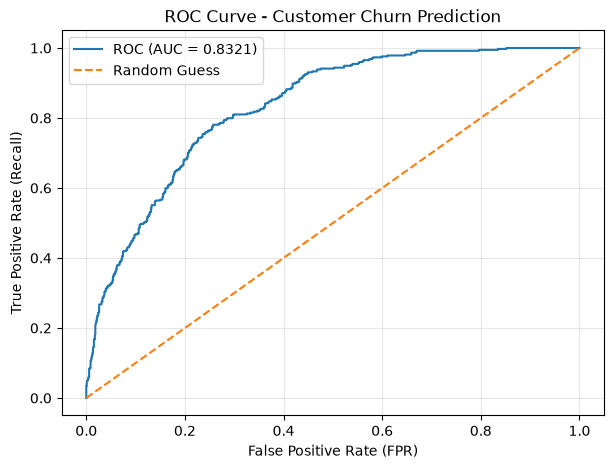

In [77]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

# 根据真实标签和预测概率计算ROC曲线
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

# 绘制ROC曲线
plt.figure(figsize=(7, 5))

plt.plot(fpr, tpr, label=f"ROC (AUC = {roc_auc:.4f})")

# 绘制随机猜测的参考线
plt.plot([0, 1], [0, 1], "--", label="Random Guess")

plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve - Customer Churn Prediction")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

### 5.8 模型评估总结

本项目基于 IBM Telco Customer Churn 数据集，使用 Logistic Regression 构建了客户流失预测模型。

模型在测试集上的 Accuracy 为 78.64%，Precision 为 62.29%，Recall 为 49.47%，F1-score 为 55.14%，ROC-AUC 为 0.8321。

结果表明，模型具有一定的客户流失风险区分能力，但在默认 50% 分类阈值下，仍遗漏了约一半的真实流失客户。

因此，模型目前可以作为风险分析的初步工具，但在实际客户留存决策中，还需要进一步研究分类阈值和业务成本。

## 6. 分类阈值优化

### 6.1 比较50%与40%分类阈值

本阶段不重新训练模型，只调整分类阈值，观察TP、TN、FP、FN的变化，以及不同阈值对客户留存决策的影响。

In [78]:
y_prob = churn_pipeline.predict_proba(x_test)[:, 1]
y_pred_50 = (y_prob >= 0.5).astype(int)
y_pred_40 = (y_prob >= 0.4).astype(int)

In [79]:
from sklearn.metrics import confusion_matrix
cm_50 = confusion_matrix(y_test, y_pred_50, labels = [0, 1])
cm_40 = confusion_matrix(y_test, y_pred_40, labels = [0, 1])
print("50%阈值：")
print(cm_50)
print("40%阈值：")
print(cm_40)

50%阈值：
[[923 112]
 [189 185]]
40%阈值：
[[848 187]
 [132 242]]


In [80]:
assert len(y_pred_40) == len(y_test)
assert cm_40[1, 0] <= cm_50[1, 0] 
print("单元检查通过")

单元检查通过


In [81]:
# 检查降低阈值后TN不会增加
assert cm_40[0, 0] <= cm_50[0, 0]

# 检查降低阈值后FN不会增加
assert cm_40[1, 0] <= cm_50[1, 0]

print("Day 5 阈值变化单元测试通过！")

Day 5 阈值变化单元测试通过！


In [82]:
assert cm_40[1, 0] <= cm_50[1, 0]
assert cm_40[0, 0] <= cm_50[0, 0]
assert cm_40[1, 0] + cm_40[1, 1] == cm_50[1, 0] + cm_50[1, 1]
print("三个单元测试全部通过！")

三个单元测试全部通过！


### 6.2 比较不同阈值下的 Precision 和 Recall

通过计算 Precision 和 Recall，比较降低分类阈值带来的客户识别能力与误报比例变化。

In [83]:
from sklearn.metrics import precision_score, recall_score
p50 = precision_score(y_test, y_pred_50)
p40 = precision_score(y_test, y_pred_40)
r40 = recall_score(y_test, y_pred_40)
r50 = recall_score(y_test, y_pred_50)
print(f"50%阈值：Precision={p50:.2%}, Recall={r50:.2%}")
print(f"40%阈值：Precision={p40:.2%}, Recall={r40:.2%}")

50%阈值：Precision=62.29%, Recall=49.47%
40%阈值：Precision=56.41%, Recall=64.71%


In [84]:
assert r40 >= r50
assert cm_40[1, 0] + cm_40[1, 1] == 374
print("Day 5 第二阶段单元测试通过！")

Day 5 第二阶段单元测试通过！


### 6.3 客户留存成本模拟

本节基于模型的混淆矩阵，对不同分类阈值进行简化成本比较。

假设：
- 每联系一名预测流失客户，成本为10元。
- 每遗漏一名真正流失的客户，预期机会损失为100元。
- TN不产生额外联系成本。

以上参数均为教学假设，并非企业真实经营数据。

模拟总成本 = 联系成本 × (TP + FP) + 漏报机会成本 × FN

In [85]:
# 从50%阈值的混淆矩阵提取数据
tp_50 = cm_50[1, 1]
fp_50 = cm_50[0, 1]
fn_50 = cm_50[1, 0]

# 从40%阈值的混淆矩阵提取数据
tp_40 = cm_40[1, 1]
fp_40 = cm_40[0, 1]
fn_40 = cm_40[1, 0]

print("50%阈值：", tp_50, fp_50, fn_50)
print("40%阈值：", tp_40, fp_40, fn_40)

50%阈值： 185 112 189
40%阈值： 242 187 132


In [86]:
# 设置模拟成本参数
contact_cost = 10
missed_cost = 100

# 计算50%阈值的模拟成本
cost_50 = contact_cost * (tp_50 + fp_50) + missed_cost * fn_50

# 计算40%阈值的模拟成本
cost_40 = contact_cost * (tp_40 + fp_40) + missed_cost * fn_40

# 计算降低阈值后减少的模拟成本
cost_saved = cost_50 - cost_40

print(f"50%阈值模拟成本：{cost_50} 元")
print(f"40%阈值模拟成本：{cost_40} 元")
print(f"模拟成本减少：{cost_saved} 元")

50%阈值模拟成本：21870 元
40%阈值模拟成本：17490 元
模拟成本减少：4380 元


In [87]:
# 测试1：50%阈值的模拟成本是否计算正确
assert cost_50 == 21870

# 测试2：40%阈值的模拟成本是否计算正确
assert cost_40 == 17490

# 测试3：两个阈值下的实际流失人数应当一致
assert fn_50 + tp_50 == fn_40 + tp_40

# 测试4：当前假设下40%阈值的模拟成本更低
assert cost_40 < cost_50

print("Day 5 成本模拟单元测试全部通过！")

Day 5 成本模拟单元测试全部通过！


### 6.4 成本参数敏感性分析

定义成本计算函数，在保持模型预测结果不变的情况下，
比较不同联系成本和漏报机会成本对阈值选择的影响。

所有成本参数均为假设值，不代表企业真实成本。

In [88]:
def calculate_cost(cm, contact_cost, missed_cost):
    tp = cm[1, 1]
    fp = cm[0, 1]
    fn = cm[1, 0]
    total_cost = contact_cost * (tp + fp) +missed_cost * fn
    return total_cost

cost_50_new = calculate_cost(cm_50, 10, 20)
cost_40_new = calculate_cost(cm_40, 10, 20)

print("50%阈值成本：", cost_50_new)
print("40%阈值成本：", cost_40_new)

50%阈值成本： 6750
40%阈值成本： 6930


In [89]:
assert cost_50_new == 6750
assert cost_40_new == 6930
print("敏感性分析单元测试通过！")

敏感性分析单元测试通过！


### 6.5 分类阈值的模拟成本平衡点

计算50%与40%两个候选阈值的成本平衡点。

假设每次联系成本固定为10元，分析每名漏报客户的预期机会成本达到多少时，两种阈值的总成本相同。

In [90]:
additional_contacts = (tp_40 + fp_40) - (tp_50 + fp_50)
avoided_fn = fn_50 - fn_40
contact_cost = 10
break_even_fn_cost = additional_contacts * contact_cost / avoided_fn
print(f"新增联系人数：{additional_contacts}")
print(f"减少FN人数：{avoided_fn}")
print(f"FN成本平衡点：{break_even_fn_cost:.2f} 元")

新增联系人数：132
减少FN人数：57
FN成本平衡点：23.16 元


In [91]:
# 验证新增联系人数
assert additional_contacts == 132

# 验证减少漏报人数
assert avoided_fn == 57

# 使用平衡点计算两个阈值的成本
cost_50_equal = calculate_cost(cm_50, 10, break_even_fn_cost)
cost_40_equal = calculate_cost(cm_40, 10, break_even_fn_cost)

# 验证两种成本几乎相等
assert abs(cost_50_equal - cost_40_equal) < 0.000001

print("Day 5 成本平衡点单元测试通过！")

Day 5 成本平衡点单元测试通过！


## 7. 客户流失风险分层与留存优先级

本节利用逻辑回归模型的预测概率，对客户进行风险分层和排序，
形成模拟客户留存优先级名单。

风险等级阈值为教学假设，不代表经过验证的最优业务策略。

In [92]:
import pandas as pd
risk_df = x_test.copy()
risk_df["churn_probability"] = churn_pipeline.predict_proba(x_test)[:,1]
risk_df["risk_level"] = pd.cut(risk_df["churn_probability"], bins = [-float("inf"), 0.4, 0.7, float("inf")], labels = ["低风险", "中风险", "高风险"], right = False)
print(risk_df["risk_level"].value_counts())


risk_level
低风险    980
中风险    384
高风险     45
Name: count, dtype: int64


In [93]:
weekly_capacity = 100
priority_list = risk_df.sort_values(by = "churn_probability", ascending = False).head(weekly_capacity)
display(priority_list.head(10))

,tenure,MonthlyCharges,Contract,InternetService,TechSupport,churn_probability,risk_level
2246,1,102.45,Month-to-month,Fiber optic,No,0.752472,高风险
6894,3,105.90,Month-to-month,Fiber optic,No,0.747329,高风险
3085,3,105.35,Month-to-month,Fiber optic,No,0.746264,高风险
2753,1,95.65,Month-to-month,Fiber optic,No,0.739267,高风险
6866,1,95.45,Month-to-month,Fiber optic,No,0.738871,高风险
3380,1,95.10,Month-to-month,Fiber optic,No,0.738179,高风险
2797,3,100.95,Month-to-month,Fiber optic,No,0.737632,高风险
4678,2,94.20,Month-to-month,Fiber optic,No,0.730255,高风险
383,1,90.85,Month-to-month,Fiber optic,No,0.729675,高风险
1401,4,99.80,Month-to-month,Fiber optic,No,0.729193,高风险


In [94]:
# 客户数量应当保持不变
assert len(risk_df) == len(x_test)

# 每名客户都应该有风险等级
assert risk_df["risk_level"].notna().all()

# 优先联系名单不超过100名
assert len(priority_list) <= 100

print("Day 6 风险分层检查通过！")

Day 6 风险分层检查通过！


In [95]:
priority_list["risk_level"].value_counts()

risk_level
中风险    55
高风险    45
低风险     0
Name: count, dtype: int64

In [96]:
risk_df.groupby("risk_level", observed = True)["tenure"].mean().round(1)

risk_level
低风险    40.2
中风险    14.2
高风险     2.5
Name: tenure, dtype: float64

In [97]:
risk_df.groupby("risk_level", observed = True)["MonthlyCharges"].mean().round(2)

risk_level
低风险    57.09
中风险    78.93
高风险    89.81
Name: MonthlyCharges, dtype: float64

In [98]:
contract_percent = pd.crosstab(risk_df["risk_level"], risk_df["Contract"], normalize = "index").mul(100).round(1)
display(contract_percent)

Contract,Month-to-month,One year,Two year
risk_level,,,
低风险,35.5,30.2,34.3
中风险,99.0,1.0,0.0
高风险,100.0,0.0,0.0


In [99]:
contract_risk = pd.crosstab(
    risk_df["Contract"],
    risk_df["risk_level"],
    normalize="index"
).mul(100).round(1)

display(contract_risk)

risk_level,低风险,中风险,高风险
Contract,,,
Month-to-month,45.0,49.2,5.8
One year,98.7,1.3,0.0
Two year,100.0,0.0,0.0


In [100]:
risk_df["actual_churn"] = y_test
risk_df[["churn_probability", "risk_level", "actual_churn"]].head(10)

,churn_probability,risk_level,actual_churn
437,0.044436,低风险,0
2280,0.596910,中风险,0
2235,0.114344,低风险,0
4460,0.463526,中风险,0
3761,0.023664,低风险,0
5748,0.612422,中风险,0
3568,0.493590,中风险,0
2976,0.124493,低风险,0
5928,0.007334,低风险,0
1639,0.313393,低风险,1


In [101]:
risk_df.groupby("risk_level", observed = True)["actual_churn"].mean().mul(100).round(1)

risk_level
低风险    13.5
中风险    53.6
高风险    80.0
Name: actual_churn, dtype: float64

In [102]:
top100_actual = risk_df.loc[priority_list.index, "actual_churn"]
print("真实流失人数:", top100_actual.sum())
print(f"名单命中率: {top100_actual.mean():.1%}",)

真实流失人数: 80
名单命中率: 80.0%


### 7.1 客户风险分层与留存优先级分析总结

基于 Logistic Regression 模型的预测流失概率，
将1409名测试客户划分为低、中、高三个风险等级。

分析发现：
- 高风险组45人，实际流失率为80%。
- 高风险客户平均在网2.5个月，平均月费89.81。
- 高风险组全部使用月付合同。
- 按预测概率排序的前100名客户中，80人真实流失。
- Precision@100为80%，Recall@100约为21.4%。

结果说明，该模型在当前测试数据上具有一定的
客户流失风险识别与排序能力，可为客户留存优先级
制定提供参考。

局限性：
风险阈值及联系名额为模拟设定；模型结果不代表
实际干预效果，正式应用前还需完成验证集调参、
成本评估及业务效果验证。

## 8. 客户流失风险可视化与业务报告

### 8.1 不同风险等级的真实流失率

通过柱状图比较低、中、高风险客户的真实流失率，
检验模型划分的风险等级是否具有实际区分能力。

图片保存数量: D:\pythonProject\customer-churn-analysis\reports\figures\churn_rate_by_risk.png


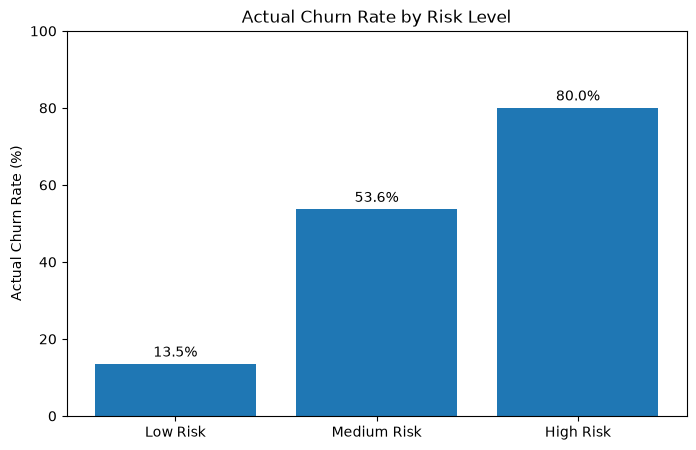

In [103]:
import matplotlib.pyplot as plt
risk_rates = risk_df.groupby("risk_level", observed = True)["actual_churn"].mean()*100
plt.figure(figsize = (8, 5))
bars= plt.bar(["Low Risk", "Medium Risk", "High Risk"], risk_rates.values)
plt.bar_label(bars, fmt = "%.1f%%", padding =3)
plt.title("Actual Churn Rate by Risk Level")
plt.ylabel("Actual Churn Rate (%)")
plt.ylim(0, 100)
from pathlib import Path
project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent
save_path = project_root/"reports"/"figures"/"churn_rate_by_risk.png"
plt.savefig(save_path, dpi = 300, bbox_inches = "tight")
print("图片保存数量:", save_path.resolve())

plt.show()

### 8.2 不同风险等级客户的平均在网时长

比较低、中、高风险客户的平均在网月数，
分析模型风险评分与客户在网时长之间的关系。

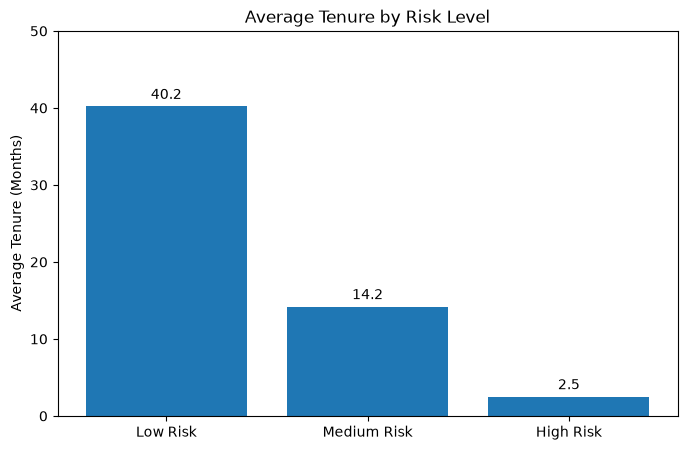

In [104]:
tenure_avg = risk_df.groupby("risk_level")["tenure"].mean().round(1)
plt.figure(figsize = (8, 5))
bars = plt.bar(["Low Risk", "Medium Risk", "High Risk"], tenure_avg.values)
plt.bar_label(bars, fmt="%.1f", padding = 3)
plt.title("Average Tenure by Risk Level")
plt.ylabel("Average Tenure (Months)")
plt.ylim(0, 50)
save_path = project_root / "reports" / "figures" / "average_tenure_by_risk.png"
plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()


### 8.3 不同风险等级客户的平均月费

比较不同风险等级客户的平均月费，
分析模型预测风险与客户月费之间的关系。

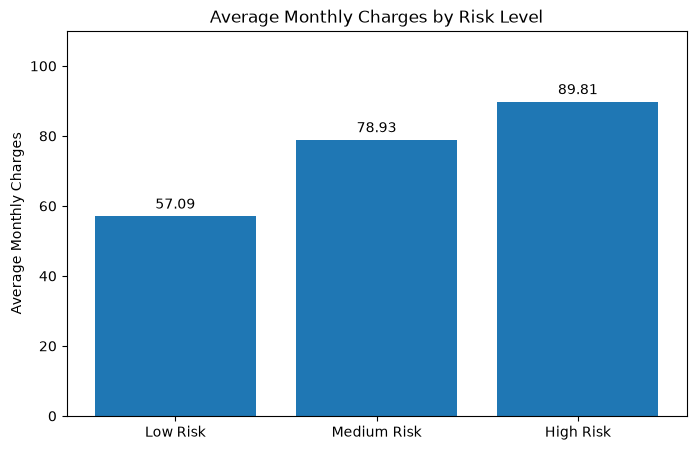

In [105]:
charges_avg = risk_df.groupby("risk_level")["MonthlyCharges"].mean().round(2)
plt.figure(figsize = (8, 5))
bars = plt.bar(["Low Risk", "Medium Risk", "High Risk"], charges_avg)
plt.bar_label(bars, fmt="%.2f", padding = 3)
plt.title("Average Monthly Charges by Risk Level")
plt.ylabel("Average Monthly Charges")
plt.ylim(0, 110)
save_path = project_root/"reports"/"figures"/"average_monthly_charges_by_risk.png"
plt.savefig(save_path, dpi = 300, bbox_inches = "tight")
plt.show()

### 8.4 不同风险等级的合同类型分布

通过100%堆叠柱状图，比较不同风险等级客户的合同类型结构。

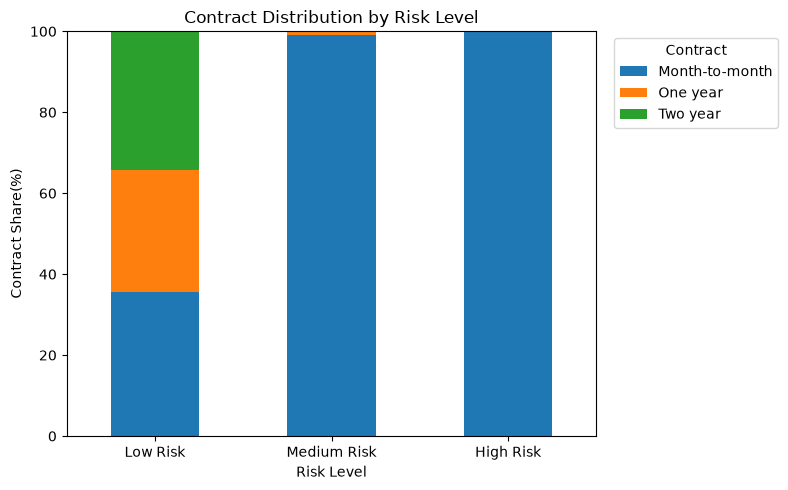

In [106]:
ax = contract_percent.plot(kind = "bar", stacked = True, figsize = (8, 5))
ax.set_xticklabels(["Low Risk", "Medium Risk", "High Risk"], rotation = 0)
ax.set_title("Contract Distribution by Risk Level")
ax.set_ylabel("Contract Share(%)")
ax.set_xlabel("Risk Level")
ax.set_ylim(0, 100)
plt.legend(title= "Contract", bbox_to_anchor = (1.02, 1), loc = "upper left")
plt.tight_layout()
save_path = project_root/"reports"/"figures"/"contract_distribution_by_risk.png"
plt.savefig(save_path, dpi = 300, bbox_inches = "tight")
plt.show()

### 8.5 客户流失风险分析的主要发现

本项目通过机器学习模型对客户进行风险分层，并结合
真实流失标签和客户特征分析，得到以下结果：

1. 风险等级越高，实际流失率越高。
   低、中、高风险组的实际流失率分别为13.5%、53.6%和80%。

2. 高风险客户的平均在网时长仅为2.5个月，
   明显低于低风险客户的40.2个月。

3. 高风险客户的平均月费为89.81，
   高于低风险客户的57.09。

4. 高风险组45名客户全部使用月付合同。

业务启示：
企业可以优先调查新入网、月费较高、使用月付合同客户的
服务体验和潜在流失原因，再制定有针对性的留存策略。

注意：上述结果反映模型评分与客户特征之间的关联，
不能直接证明因果关系，也不代表干预措施一定有效。

### 9. 最终模型训练与阈值评估

根据验证集上的模拟成本比较，
在40%和50%两个候选阈值中选择40%。

使用原始训练集重新训练模型，
并在测试集上进行结果对照。

In [111]:
from sklearn.base import clone
from sklearn.metrics import confusion_matrix
selected_threshold = 0.40
final_pipeline = clone(churn_pipeline)
final_pipeline.fit(x_train, y_train)
test_prob = final_pipeline.predict_proba(x_test)[:, 1]
test_pred = (test_prob >= selected_threshold).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, test_pred, labels = [0, 1]).ravel()
print(f"最终使用的阈值：{selected_threshold:.0%}")
print(f"TP={tp}, FP={fp}, FN={fn}, TN={tn}")
precision = tp / (tp + fp)
recall = tp / (tp + fn)

cost = 10 * (tp + fp) + 25 * fn

print(f"Precision：{precision:.1%}")
print(f"Recall：{recall:.1%}")
print(f"模拟成本：{cost:.0f}")

# 确认混淆矩阵人数等于测试集人数
assert tn + fp + fn + tp == len(y_test)

print("最终模型检查通过！")

最终使用的阈值：40%
TP=242, FP=187, FN=132, TN=848
Precision：56.4%
Recall：64.7%
模拟成本：7590
最终模型检查通过！
